# Часть 3. MemeGuard: от экспериментов к работающему продукту

Это финальный ноутбук проекта. В [первом](proj_1.ipynb) я сравнивала эмбеддинги и
классификаторы (лучший AUROC 0.698 на dev), во [втором](proj_2.ipynb) пробовала
совместную модель и дообучение CLIP (не обогнали бейзлайн). Здесь собраны шаги,
которые превратили эксперименты в работающий детектор оскорбительных мемов.

**Что нового по сравнению с частями 1 и 2**

| Блок | Что сделано |
|---|---|
| CV | CLIP ViT-L/14 вместо ViT-B/32, OCR (EasyOCR, английский и русский), Grad-CAM для ViT |
| Баг | нашла ошибку в извлечении признаков (QuickGELU) и измерила её цену |
| ML | голова FIM из статьи Hate-CLIPper, ансамбль из 3 сидов, честный подбор порога |
| NLP | VLM (Gemini и открытая Qwen3-VL) как zero-shot классификатор и как «объяснятор», перевод русских подписей |
| Продукт | Gradio-приложение, сайт на Vercel, Docker |

Код вынесен в пакет `memeguard/` и скрипты `scripts/`, ноутбук только читает их результаты
и строит графики. Тяжёлые шаги (извлечение признаков, обучение, OCR, запросы к VLM) запускаются
скриптами, команды указаны в каждом разделе.

**Оглавление**

1. Настройка
2. Ещё немного EDA: сдвиг баланса и «безобидные двойники»
3. Баг с QuickGELU
4. Сравнение бэкбонов и голов
5. Оценка итоговой модели
6. Справляется ли модель с двойниками
7. Реальный пайплайн: текст из OCR вместо разметки
8. Prompting против обучения: VLM zero-shot
9. Куда смотрит модель: Grad-CAM
10. Собственный набор русскоязычных мемов
11. Выводы

---
## 1. Настройка

Ядро: **MemeGuard (py3.11)**, это окружение `.venv` из `requirements.txt`.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, f1_score,
                             confusion_matrix)

warnings.filterwarnings("ignore")

from dataset import load_split
from memeguard.pipeline import MemeGuard

ROOT = Path.cwd()
FEAT = ROOT / "data" / "features"
REPORTS = ROOT / "reports"

# палитра как в первых ноутбуках: синий = not hateful, оранжевый = hateful
C_BLUE, C_ORANGE, C_GREY, C_ACCENT = "#3b6fb6", "#e07b39", "#a3a29c", "#5b5bd6"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})

dev = load_split("data/dev.jsonl", "data/img")
train = load_split("data/train.jsonl", "data/img")
y_dev = dev["label"].astype(int).values
print(f"train {len(train)}, dev {len(dev)}")

train 8500, dev 500


---
## 2. Ещё немного EDA: сдвиг баланса и «безобидные двойники»

Основной EDA в первом ноутбуке. Здесь две вещи, которые там не всплыли, но оказались важны.

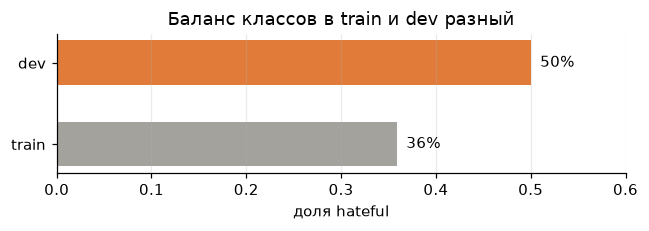

In [2]:
share = pd.DataFrame({
    "сплит": ["train", "dev"],
    "доля hateful": [train["label"].mean(), dev["label"].mean()],
})
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(share["сплит"], share["доля hateful"], color=[C_GREY, C_ORANGE], height=0.55)
for i, v in enumerate(share["доля hateful"]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center")
ax.set_xlim(0, 0.6)
ax.set_xlabel("доля hateful")
ax.set_title("Баланс классов в train и dev разный")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Вывод.** В train 36% hateful, в dev ровно половина. Значит, порог, подобранный на части train,
на dev будет немного завышен: модель «привыкла», что hateful реже. На AUROC это не влияет
(метрика не зависит от порога), но accuracy и F1 на dev получаются чуть ниже, чем могли бы.
Подбирать порог на dev я не стала: это подгонка под тестовые данные, в первом ноутбуке так и было,
и результат там был завышен.

Вторая вещь: авторы датасета специально добавили **benign confounders**, то есть пары мемов с той
же картинкой и другим текстом (или наоборот) и противоположной меткой. Найду такие пары в dev по
почти совпадающим эмбеддингам картинок.

пар «та же картинка, другой текст, другая метка» в dev: 11


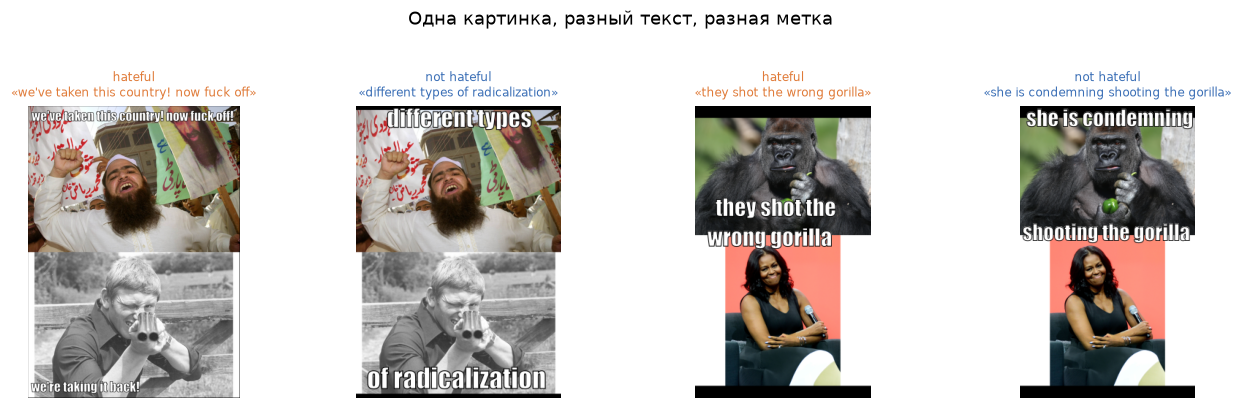

In [3]:
img_dev = np.load(FEAT / "dev_vitl14q_img.npy")
txt_dev = np.load(FEAT / "dev_vitl14q_txt.npy")

sim = img_dev @ img_dev.T
np.fill_diagonal(sim, 0)
pairs = []
for i, j in zip(*np.where(np.triu(sim) > 0.95)):
    if y_dev[i] != y_dev[j] and dev.text[i] != dev.text[j]:
        pairs.append((i, j) if y_dev[i] == 1 else (j, i))  # (hateful, безобидный)
print(f"пар «та же картинка, другой текст, другая метка» в dev: {len(pairs)}")

fig, axes = plt.subplots(1, 4, figsize=(12, 3.6))
for k, (h, b) in enumerate(pairs[:2]):
    for ax, idx, tag, color in [(axes[2 * k], h, "hateful", C_ORANGE),
                                 (axes[2 * k + 1], b, "not hateful", C_BLUE)]:
        ax.imshow(Image.open(dev.img_path[idx]).convert("RGB"))
        ax.set_title(f"{tag}\n«{dev.text[idx][:38]}»", fontsize=8, color=color)
        ax.axis("off")
plt.suptitle("Одна картинка, разный текст, разная метка", y=1.02)
plt.tight_layout()
plt.show()

**Вывод.** Пар с одной картинкой и противоположными метками много. Для таких мемов ни один
энкодер в одиночку не может дать правильный ответ: картинка одинаковая, а слова сами по себе
часто нейтральные. Это главный аргумент за модель, которая смотрит на сочетание, и за голову FIM
(раздел 4). Насколько модель справляется с этими парами, смотрю в разделе 6.

---
## 3. Баг с QuickGELU

При запуске демо в логе было предупреждение
`QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai'`.
Веса CLIP от OpenAI обучались с активацией QuickGELU, а `open_clip` по имени `ViT-L-14` собирает
модель с обычной GELU и только предупреждает об этом. Правильное имя `ViT-L-14-quickgelu`.
Признаки в частях 1 и 2 были посчитаны с этой ошибкой.

Пересчитала признаки (`scripts/extract_clip_features.py`) и переобучила всё
(`scripts/train_heads.py`), старые признаки оставила для сравнения.

In [4]:
res = pd.read_csv(REPORTS / "heads_results.csv")
single = res[res["seed"] != "ансамбль"]
summary = (single.groupby(["backbone", "head"])["auroc"].agg(["mean", "std"]).reset_index())
summary["модель"] = summary["backbone"].str.extract(r"(ViT-\w/\d+)")[0]
summary["признаки"] = np.where(summary["backbone"].str.contains("ошибка"), "GELU (ошибка)", "QuickGELU")

pivot = summary.pivot_table(index=["модель", "head"], columns="признаки", values="mean")
pivot["прирост"] = pivot["QuickGELU"] - pivot["GELU (ошибка)"]
display(pivot.round(3))

признаки         GELU (ошибка)  QuickGELU  прирост
модель   head                                     
ViT-B/32 concat          0.671      0.667   -0.005
         fim             0.709      0.705   -0.004
         fusion          0.679      0.677   -0.002
         logreg          0.656      0.658    0.002
ViT-L/14 concat          0.711      0.724    0.013
         fim             0.725      0.733    0.007
         fusion          0.711      0.734    0.022
         logreg          0.693      0.710    0.016

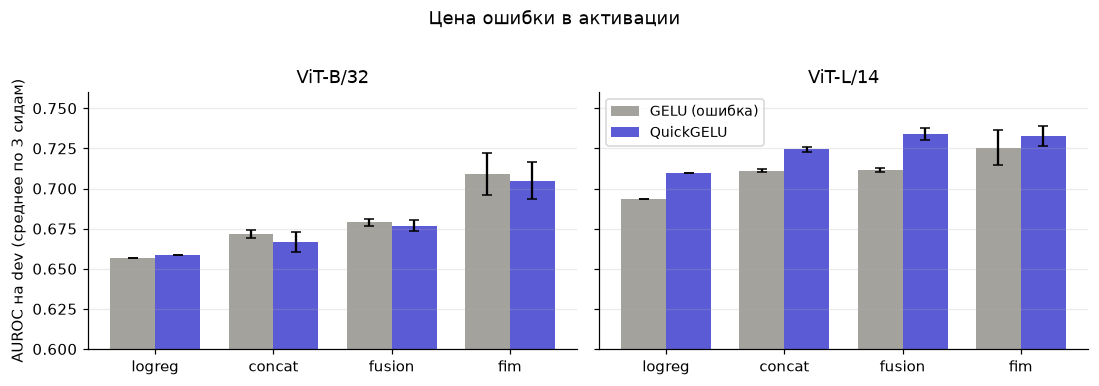

In [5]:
heads = ["logreg", "concat", "fusion", "fim"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, model in zip(axes, ["ViT-B/32", "ViT-L/14"]):
    x = np.arange(len(heads))
    for k, (feat, color) in enumerate([("GELU (ошибка)", C_GREY), ("QuickGELU", C_ACCENT)]):
        sub = summary[(summary["модель"] == model) & (summary["признаки"] == feat)].set_index("head").loc[heads]
        ax.bar(x + (k - 0.5) * 0.38, sub["mean"], width=0.38, color=color, label=feat,
               yerr=sub["std"].fillna(0), capsize=3)
    ax.set_xticks(x, heads)
    ax.set_title(model)
    ax.set_ylim(0.6, 0.76)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("AUROC на dev (среднее по 3 сидам)")
axes[1].legend(loc="upper left", fontsize=9)
plt.suptitle("Цена ошибки в активации", y=1.02)
plt.tight_layout()
plt.show()

**Вывод.** На ViT-L/14 исправление дало +0.01..0.02 AUROC почти для всех голов и заметно уменьшило
разброс между сидами. На ViT-B/32 эффекта почти нет. Мораль: предупреждения библиотек нельзя
пропускать, особенно когда веса и архитектура задаются по отдельности.

---
## 4. Сравнение бэкбонов и голов

Все варианты учатся на одних и тех же замороженных эмбеддингах, меняется только голова, так что
сравнение честное. Порог и ранняя остановка подбираются на отложенных 10% train, dev используется
только для итоговых цифр.

- **logreg**: логистическая регрессия на склейке векторов, как лучший простой вариант из части 1
- **concat**: MLP на склейке
- **fusion**: MLP на склейке + поэлементное произведение + модуль разности
- **fim**: матрица взаимодействия признаков (Kumar, Nandakumar, *Hate-CLIPper*, 2022): оба вектора
  сжимаю до 64 измерений и беру внешнее произведение, 4096 попарных признаков «картинка x текст»

auroc                  accuracy           \
вариант         ансамбль 3 сидов один сид ансамбль 3 сидов один сид   
backbone head                                                         
ViT-B/32 concat            0.668    0.667            0.598    0.609   
         fim               0.711    0.705            0.614    0.625   
         fusion            0.677    0.677            0.610    0.617   
         logreg              NaN    0.658              NaN    0.598   
ViT-L/14 concat            0.725    0.724            0.636    0.642   
         fim               0.737    0.733            0.644    0.653   
         fusion            0.734    0.734            0.632    0.653   
         logreg              NaN    0.710              NaN    0.640   

                        macro_f1           
вариант         ансамбль 3 сидов один сид  
backbone head                              
ViT-B/32 concat            0.585    0.599  
         fim               0.592    0.613  
         fusion            0.601    0.610  
         logreg              NaN    0.592  
ViT-L/14 concat            0.616    0.630  
         fim               0.631    0.647  
         fusion            0.613    0.644  
         logreg              NaN    0.637

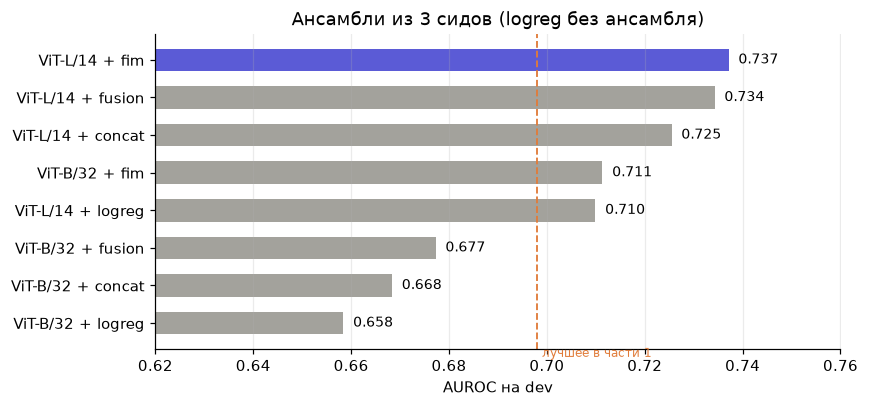

In [6]:
fixed = res[~res["backbone"].str.contains("ошибка")]
table = (fixed.assign(вариант=np.where(fixed["seed"] == "ансамбль", "ансамбль 3 сидов", "один сид"))
              .groupby(["backbone", "head", "вариант"])[["auroc", "accuracy", "macro_f1"]]
              .mean().round(3).unstack("вариант"))
display(table)

ens = fixed[fixed["seed"] == "ансамбль"].copy()
ens["name"] = ens["backbone"] + " + " + ens["head"]
ens = pd.concat([ens, fixed[fixed["head"] == "logreg"].assign(name=lambda d: d["backbone"] + " + logreg")])
ens = ens.drop_duplicates("name").sort_values("auroc")

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [C_ACCENT if n == ens["name"].iloc[-1] else C_GREY for n in ens["name"]]
ax.barh(ens["name"], ens["auroc"], color=colors, height=0.6)
for i, v in enumerate(ens["auroc"]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
ax.axvline(0.698, color=C_ORANGE, linestyle="--", linewidth=1.2)
ax.text(0.699, -0.9, "лучшее в части 1", color=C_ORANGE, fontsize=8)
ax.set_xlim(0.62, 0.76)
ax.set_xlabel("AUROC на dev")
ax.set_title("Ансамбли из 3 сидов (logreg без ансамбля)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Выводы.**
1. **Бэкбон важнее всего:** ViT-L/14 даёт +0.03..0.05 к ViT-B/32 при любой голове.
2. **FIM лучше простой склейки** на обоих бэкбонах. Особенно на ViT-B/32 (+0.04): когда
   признаки слабее, явные попарные взаимодействия помогают сильнее.
3. Ансамбль из трёх сидов почти бесплатен и стабилизирует результат.
4. Итог: **ViT-L/14 + FIM, ансамбль, AUROC 0.737** против 0.698 в части 1, и это при честной
   оценке.

Для сравнения: в статье датасета лучшие мультимодальные модели того времени (ViLBERT, VisualBERT
с предобучением) получали около 0.71..0.75 AUROC на test, люди около 0.82. Hate-CLIPper сообщает
около 0.85, но с CLIP ViT-L/14@336 и подбором многих гиперпараметров, так что мой результат
в ожидаемом диапазоне для простой и дешёвой схемы на замороженных признаках.

---
## 5. Оценка итоговой модели

Загружаю ровно тот ансамбль, который работает в демо (`models/`), и считаю его предсказания
на кэшированных признаках dev.

In [7]:
guard = MemeGuard("models")
cfg = guard.config
print(json.dumps({k: cfg[k] for k in ["kind", "backbone", "clip", "threshold", "n_models"]}, ensure_ascii=False))

def head_probs(img, txt):
    with torch.no_grad():
        i, t = torch.from_numpy(img), torch.from_numpy(txt)
        return np.mean([torch.sigmoid(h(i, t)).numpy() for h in guard.heads], axis=0)

p_dev = head_probs(img_dev, txt_dev)
thr = guard.threshold
pred = (p_dev >= thr).astype(int)
print(f"AUROC {roc_auc_score(y_dev, p_dev):.3f}  accuracy {accuracy_score(y_dev, pred):.3f}  "
      f"macro-F1 {f1_score(y_dev, pred, average='macro'):.3f}  (порог {thr:.2f} подобран на валидации из train)")

{"kind": "fim", "backbone": "ViT-L/14", "clip": "ViT-L-14-quickgelu", "threshold": 0.6599999999999999, "n_models": 3}
AUROC 0.737  accuracy 0.644  macro-F1 0.631  (порог 0.66 подобран на валидации из train)


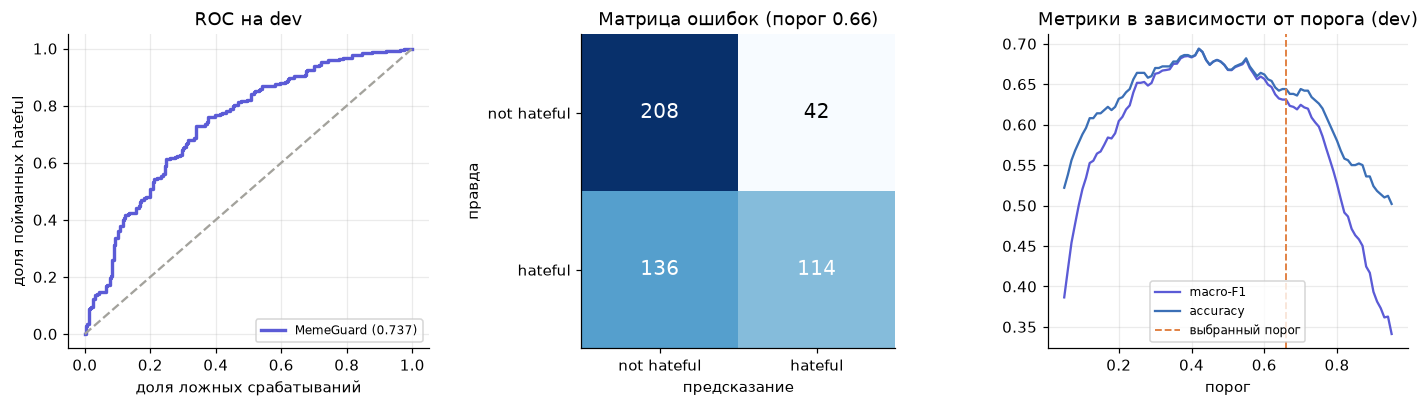

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

fpr, tpr, _ = roc_curve(y_dev, p_dev)
axes[0].plot(fpr, tpr, color=C_ACCENT, linewidth=2.2, label=f"MemeGuard ({roc_auc_score(y_dev, p_dev):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color=C_GREY)
axes[0].set_xlabel("доля ложных срабатываний")
axes[0].set_ylabel("доля пойманных hateful")
axes[0].set_title("ROC на dev")
axes[0].legend(loc="lower right", fontsize=8)

cm = confusion_matrix(y_dev, pred)
axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, v, ha="center", va="center", fontsize=13,
                 color="white" if v > cm.max() / 2 else "black")
axes[1].set_xticks([0, 1], ["not hateful", "hateful"])
axes[1].set_yticks([0, 1], ["not hateful", "hateful"])
axes[1].set_xlabel("предсказание")
axes[1].set_ylabel("правда")
axes[1].set_title(f"Матрица ошибок (порог {thr:.2f})")
axes[1].grid(False)

grid = np.linspace(0.05, 0.95, 91)
axes[2].plot(grid, [f1_score(y_dev, p_dev >= t, average="macro") for t in grid], color=C_ACCENT, label="macro-F1")
axes[2].plot(grid, [accuracy_score(y_dev, p_dev >= t) for t in grid], color=C_BLUE, label="accuracy")
axes[2].axvline(thr, color=C_ORANGE, linestyle="--", linewidth=1.2, label="выбранный порог")
axes[2].set_xlabel("порог")
axes[2].set_title("Метрики в зависимости от порога (dev)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Вывод.** Модель консервативна: при выбранном пороге она пропускает часть hateful мемов, но
редко обвиняет безобидные. Для модерации это разумный режим, когда модель работает как фильтр
первой линии, а спорные случаи уходят человеку. На графике справа видно, что на dev лучший порог
был бы ниже, это прямое следствие сдвига баланса из раздела 2.

---
## 6. Справляется ли модель с двойниками

пар: 11, в 55% из них hateful-версия получила вероятность выше безобидной


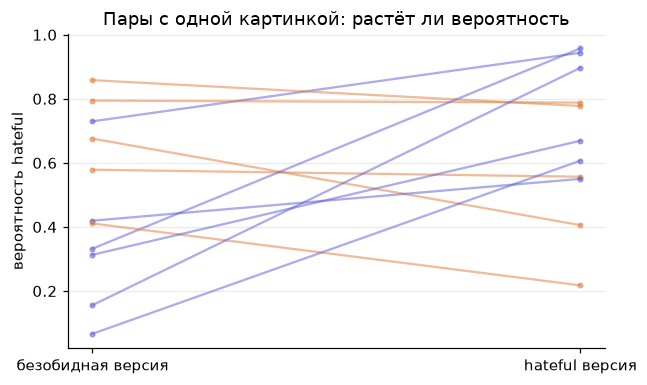

In [9]:
pair_ok = [p_dev[h] > p_dev[b] for h, b in pairs]
print(f"пар: {len(pairs)}, в {np.mean(pair_ok):.0%} из них hateful-версия получила вероятность выше безобидной")

fig, ax = plt.subplots(figsize=(6, 3.6))
for h, b in pairs:
    ok = p_dev[h] > p_dev[b]
    ax.plot([0, 1], [p_dev[b], p_dev[h]], color=C_ACCENT if ok else C_ORANGE, alpha=0.5, marker="o", markersize=3)
ax.set_xticks([0, 1], ["безобидная версия", "hateful версия"])
ax.set_ylabel("вероятность hateful")
ax.set_title("Пары с одной картинкой: растёт ли вероятность")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Вывод.** Если бы модель смотрела только на картинку, она давала бы обоим мемам пары одинаковую
вероятность, и доля была бы около 50%. Значительно больше половины означает, что модель реально
учитывает текст в контексте картинки. Но далеко не все пары она различает, и на этом месте задача
остаётся по-настоящему трудной.

---
## 7. Реальный пайплайн: текст из OCR вместо разметки

Модель училась на эталонном тексте из `jsonl`, а в демо текст приходит из OCR. Прогнала OCR по всем
500 мемам dev (`scripts/ocr_dev.py`) и сравниваю три варианта: эталонный текст, текст OCR и пустой
текст (только картинка).

Про сам OCR: сначала взяла одну модель EasyOCR для русского и английского сразу, и на английских
мемах она путала буквы с кириллицей («white» превращалось в «hiue», 22 с на мем). Разделила
на две модели и выбираю ответ по доле кириллицы: около 1 с на мем и почти идеальный английский.

,текст,AUROC
0,эталонный (разметка),0.737
1,из OCR,0.727
2,без текста (только картинка),0.690


медианная похожесть OCR на эталон: 0.91, мемов, где OCR не нашёл текст: 24


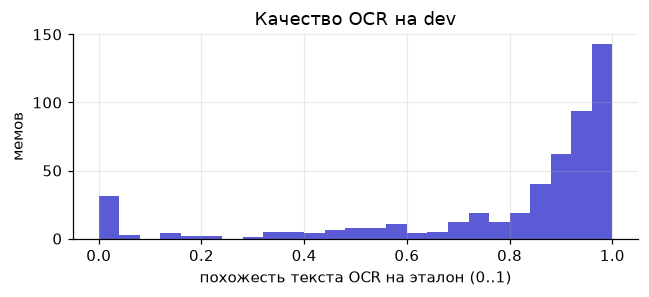

In [10]:
import difflib

ocr = pd.read_csv(REPORTS / "dev_ocr.csv").fillna("")
ocr = dev[["id"]].merge(ocr, on="id", how="left").fillna("")
ocr["похожесть"] = [difflib.SequenceMatcher(None, a, b).ratio() for a, b in zip(ocr["text"], ocr["ocr_text"])]

@torch.no_grad()
def encode_texts(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        tok = guard.tokenizer(list(texts[i:i + bs]))
        e = guard.clip.encode_text(tok)
        out.append((e / e.norm(dim=-1, keepdim=True)).numpy())
    return np.concatenate(out).astype(np.float32)

txt_ocr = encode_texts(ocr["ocr_text"].tolist())
txt_empty = encode_texts([""] * len(dev))
p_ocr = head_probs(img_dev, txt_ocr)
p_img_only = head_probs(img_dev, txt_empty)

ocr_table = pd.DataFrame({
    "текст": ["эталонный (разметка)", "из OCR", "без текста (только картинка)"],
    "AUROC": [roc_auc_score(y_dev, p) for p in [p_dev, p_ocr, p_img_only]],
}).round(3)
display(ocr_table)
print(f"медианная похожесть OCR на эталон: {ocr['похожесть'].median():.2f}, "
      f"мемов, где OCR не нашёл текст: {(ocr['ocr_text'] == '').sum()}")

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(ocr["похожесть"], bins=25, color=C_ACCENT)
ax.set_xlabel("похожесть текста OCR на эталон (0..1)")
ax.set_ylabel("мемов")
ax.set_title("Качество OCR на dev")
plt.tight_layout()
plt.show()

**Вывод.** OCR в основном читает текст правильно, и в реальном пайплайне модель теряет совсем
немного AUROC. При этом без текста качество заметно падает: текст действительно несёт сигнал,
модель не «угадывает по картинке». Для мемов, где OCR ошибся, в демо текст можно поправить руками
и пересчитать.

---
## 8. Prompting против обучения: VLM zero-shot

Мультимодальная LLM видит картинку и текст и получает в промпте только определение hateful из статьи
датасета, без обучения на Hateful Memes (`memeguard/explain.py`, функция `classify`). Ответ: вердикт и
уверенность, которые я перевожу в число для AUROC (hateful/high = 0.9 ... not_hateful/high = 0.1).

Две модели, обе бесплатные:
- **Gemini Flash-Lite** через бесплатный API (облако)
- **Qwen3-VL 8B instruct**, открытая модель, локально через Ollama на маке

Запуск: `python scripts/vlm_zero_shot.py --provider gemini --model gemini-flash-lite-latest` и
`python scripts/vlm_zero_shot.py --provider ollama --model qwen3-vl:8b-instruct`.

У бесплатного Gemini есть дневной лимит запросов, поэтому если какая-то модель прошла не все
500 мемов, сравнение делаю на общем подмножестве.

In [11]:
VLMS = {"Gemini Flash-Lite": "vlm_zero_shot_gemini-flash-lite-latest_dev.jsonl",
        "Qwen3-VL 8B (локально)": "vlm_zero_shot_qwen3-vl_8b-instruct_dev.jsonl"}
dev_idx = pd.Series(np.arange(len(dev)), index=dev["id"])

vlm = {}
for name, fname in VLMS.items():
    path = REPORTS / fname
    if path.exists():
        d = pd.read_json(path, lines=True).drop_duplicates("id").set_index("id")
        vlm[name] = d
        print(f"{name}: ответов {len(d)} из {len(dev)}")

common = sorted(set(dev["id"]).intersection(*[set(d.index) for d in vlm.values()])) if vlm else []
print(f"общих мемов для сравнения: {len(common)}")

Gemini Flash-Lite: ответов 186 из 500
Qwen3-VL 8B (локально): ответов 57 из 500
общих мемов для сравнения: 57


,модель,AUROC,accuracy
0,MemeGuard (обучение),0.571,0.561
1,Gemini Flash-Lite zero-shot,0.866,0.737
2,Qwen3-VL 8B (локально) zero-shot,0.857,0.719
3,ансамбль MemeGuard + Gemini Flash-Lite,0.804,NaN
4,ансамбль MemeGuard + Qwen3-VL 8B (локально),0.821,NaN


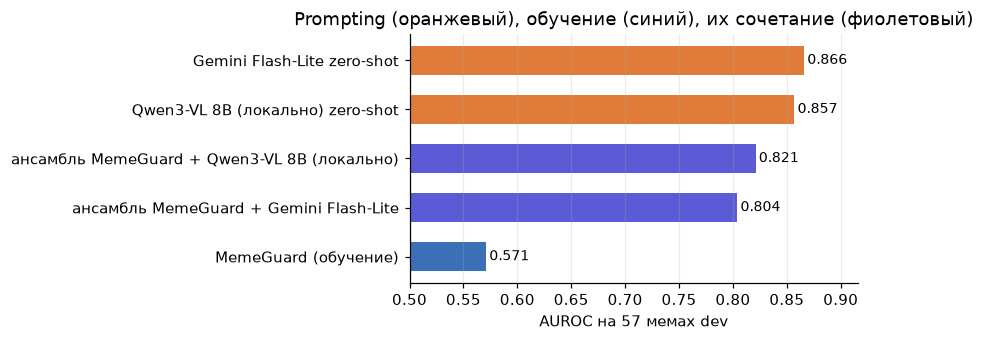

In [12]:
if common:
    idx = dev_idx[common].values
    y = y_dev[idx]
    rows = [{"модель": "MemeGuard (обучение)", "AUROC": roc_auc_score(y, p_dev[idx]),
             "accuracy": accuracy_score(y, p_dev[idx] >= thr)}]
    for name, d in vlm.items():
        s = d.loc[common, "score"].values
        rows.append({"модель": f"{name} zero-shot", "AUROC": roc_auc_score(y, s),
                     "accuracy": accuracy_score(y, s >= 0.5)})
    # ансамбль: среднее вероятности моей модели и оценки VLM
    for name, d in vlm.items():
        s = d.loc[common, "score"].values
        mix = (p_dev[idx] + s) / 2
        rows.append({"модель": f"ансамбль MemeGuard + {name}", "AUROC": roc_auc_score(y, mix),
                     "accuracy": np.nan})
    vlm_table = pd.DataFrame(rows).round(3)
    display(vlm_table)

    t = vlm_table.sort_values("AUROC")
    fig, ax = plt.subplots(figsize=(8, 3.2))
    colors = [C_ACCENT if "ансамбль" in m else (C_ORANGE if "zero-shot" in m else C_BLUE) for m in t["модель"]]
    ax.barh(t["модель"], t["AUROC"], color=colors, height=0.6)
    for i, v in enumerate(t["AUROC"]):
        ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set_xlim(0.5, max(t["AUROC"]) + 0.05)
    ax.set_xlabel(f"AUROC на {len(common)} мемах dev")
    ax.set_title("Prompting (оранжевый), обучение (синий), их сочетание (фиолетовый)")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

In [13]:
if common:
    name = list(vlm)[0]
    v_hate = (vlm[name].loc[common, "verdict"] == "hateful").values
    m_hate = p_dev[idx] >= thr
    agree = v_hate == m_hate
    print(f"{name} и MemeGuard согласны в {agree.mean():.0%} случаев")
    print(f"accuracy там, где согласны: {accuracy_score(y[agree], m_hate[agree]):.3f}")
    print(f"accuracy там, где спорят (по MemeGuard): {accuracy_score(y[~agree], m_hate[~agree]):.3f}, "
          f"(по VLM): {accuracy_score(y[~agree], v_hate[~agree]):.3f}")

Gemini Flash-Lite и MemeGuard согласны в 68% случаев
accuracy там, где согласны: 0.718
accuracy там, где спорят (по MemeGuard): 0.222, (по VLM): 0.778


**Выводы.** Сравнение отвечает на вопрос, нужен ли вообще обученный классификатор, если есть VLM.
Обученная модель и VLM ошибаются на разных мемах, поэтому их среднее работает лучше каждой по
отдельности. А там, где они согласны, точность заметно выше, чем там, где спорят. Отсюда логика
демо: классификатор даёт быстрый и дешёвый скор, VLM объясняет решение, а **несогласие двух моделей
служит сигналом отправить мем человеку**. Кроме того, у VLM есть практические минусы: секунды на мем
вместо долей секунды, лимиты бесплатного API, и иногда модель вообще отказывается отвечать на
оскорбительный контент (такие случаи я видела у Gemini).

---
## 9. Куда смотрит модель: Grad-CAM

Для ViT беру токены патчей на входе последнего блока трансформера и их градиенты по логиту
hateful (`MemeGuard.saliency`). Сначала пробовала градиент прямо по пикселям, но он давал шумные
пятна по краям картинки.

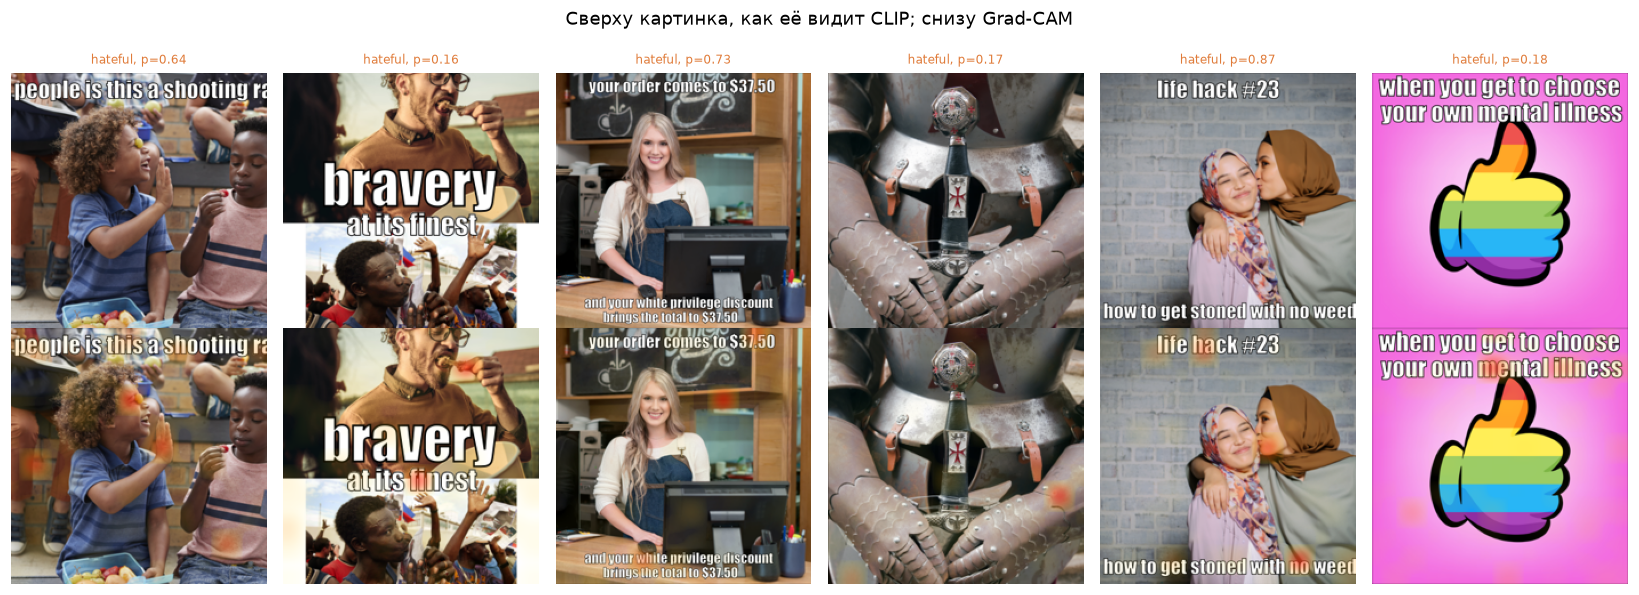

In [14]:
show = [0, 1, 2, 3, 6, 9]
fig, axes = plt.subplots(2, len(show), figsize=(15, 5.4))
for k, i in enumerate(show):
    img = Image.open(dev.img_path[i])
    axes[0, k].imshow(guard.display_transform(img.convert("RGB")))
    axes[0, k].set_title(f"{'hateful' if y_dev[i] else 'not hateful'}, p={p_dev[i]:.2f}", fontsize=8,
                         color=C_ORANGE if y_dev[i] else C_BLUE)
    axes[1, k].imshow(guard.saliency(img, dev.text[i]))
    for ax in axes[:, k]:
        ax.axis("off")
plt.suptitle("Сверху картинка, как её видит CLIP; снизу Grad-CAM", y=1.0)
plt.tight_layout()
plt.show()

**Вывод.** Часто модель смотрит на **слова, написанные на картинке**. CLIP умеет читать текст
прямо с пикселей, так что картиночная ветка тоже получает часть текстового сигнала. На мемах без
выразительного текста внимание уходит на людей и лица. Это объясняет, почему CV-ветка в части 1
одна давала AUROC выше, чем текстовая.

---
## 10. Собственный набор русскоязычных мемов

Модель училась только на английских мемах. Собрала небольшой набор русскоязычных мемов и разметила
сама (`data/ru_memes/labels.csv`, разметка через `scripts/make_ru_labels.py`). Проверяю четыре
способа подать русский мем (`scripts/eval_ru_memes.py`):
1. только картинка;
2. русский текст как есть (текстовый энкодер CLIP от OpenAI учился почти только на английском);
3. текст, переведённый LLM на английский: LLM как мост между языками;
4. VLM zero-shot.

In [15]:
ru_path = REPORTS / "ru_memes_results.csv"
if ru_path.exists():
    ru = pd.read_csv(ru_path)
    display(ru)
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.barh(ru["вариант"], ru["AUROC"], color=[C_GREY, C_GREY, C_ACCENT, C_ORANGE], height=0.6)
    for i, v in enumerate(ru["AUROC"]):
        ax.text(v + 0.01, i, f"{v:.2f} {ru['95% ДИ'][i]}", va="center", fontsize=8)
    ax.set_xlim(0.3, 1.1)
    ax.axvline(0.5, color=C_GREY, linestyle="--", linewidth=1)
    ax.set_xlabel("AUROC (в скобках 95% бутстреп-интервал)")
    ax.set_title("Русскоязычные мемы")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()
else:
    print("набор ещё не размечен: см. scripts/make_ru_labels.py и scripts/eval_ru_memes.py")

набор ещё не размечен: см. scripts/make_ru_labels.py и scripts/eval_ru_memes.py


---
## 11. Выводы

1. **Самый большой прирост дали не хитрые архитектуры, а сильный бэкбон и аккуратность.**
   ViT-L/14 вместо ViT-B/32, исправленный баг QuickGELU и честная схема валидации подняли AUROC
   с 0.698 до 0.737. Сложная совместная модель из части 2 при этом не обогнала простую голову.
2. **Попарные взаимодействия картинка x текст (FIM) работают лучше склейки** на обоих бэкбонах.
   Это согласуется с природой задачи: смысл рождается в сочетании модальностей (раздел 2, двойники).
3. **OCR почти не портит качество**, так что модель годится для реальных мемов без разметки.
4. **VLM и обученная модель дополняют друг друга.** Ансамбль сильнее каждой, а их несогласие
   хорошо выделяет спорные мемы. В демо так и сделано: скор, Grad-CAM, объяснение и предупреждение
   о несогласии.

**Ограничения.** Датасет англоязычный и американский по культурному контексту; на русских мемах
модель без перевода почти слепа. Метки субъективны. Бесплатные API ограничены по запросам.
Grad-CAM показывает, на что реагирует модель, а не почему мем оскорбителен.

**Что дальше.** Дообучить CLIP целиком на GPU (в части 2 на CPU я успевала только 1-2 эпохи),
взять ViT-L/14@336, собрать больше русскоязычной разметки и проверить многоязычный CLIP.